In [5]:
import torch
import importlib.util
device = "cuda"
torch.manual_seed(42)

In [8]:
import xarray as xr

# Open the Othello dataset
url = "hf://datasets/aviralchawla/metaothello/train_classic_20M.zarr"
dataset = xr.open_zarr(url)

# Load the first 5 games
games = dataset["seqs"].isel(game=slice(0, 5)).values

print("Shape:", games.shape)
print("First game:", games[0])


Shape: (5, 60)
First game: [45 44 27 46 51 19 30 35 55 38 20 22 34 58 14 18 53 13 43 54 11 39  4  6
 63 41 31 61 25 24 21 33 62 10  1  2 60 52 49  9 32 56  7 47 17 40 26 23
 59  5 64  3 48  8 16 50 42 15 57 65]


'[Errno -3] Temporary failure in name resolution' thrown while requesting GET https://huggingface.co/datasets/aviralchawla/metaothello/resolve/main/train_classic_20M.zarr/seqs/7.2
'[Errno -3] Temporary failure in name resolution' thrown while requesting GET https://huggingface.co/datasets/aviralchawla/metaothello/resolve/main/train_classic_20M.zarr/seqs/7.0
'[Errno -3] Temporary failure in name resolution' thrown while requesting GET https://huggingface.co/datasets/aviralchawla/metaothello/resolve/main/train_classic_20M.zarr/seqs/6.2
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting GET https://huggingface.co/datasets/aviralchawla/metaothello/resolve/main/train_classic_20M.zarr/seqs/7.1
Retrying in 1s [Retry 1/5].
Retrying in 1s [Retry 1/5].
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting GET https://huggingface.co/datasets/aviralchawla/metaothello/resolve/main/train_classic_20M.za

In [9]:

# Convert a token number into an Othello move
def decode_move(token):
    token = int(token)

    if token == 0:
        return "PAD"
    if token == 65:
        return "PASS"

    square = token - 1
    column = "ABCDEFGH"[square % 8]
    row = square // 8 + 1

    return column + str(row)


# Decode the first 10 tokens from our first game
first_tokens = games[0][:10]
first_moves = [decode_move(token) for token in first_tokens]

print("Token IDs:", first_tokens)
print("Moves:", first_moves)


Token IDs: [45 44 27 46 51 19 30 35 55 38]
Moves: ['E6', 'D6', 'C4', 'F6', 'C7', 'C3', 'F4', 'C5', 'G7', 'F5']


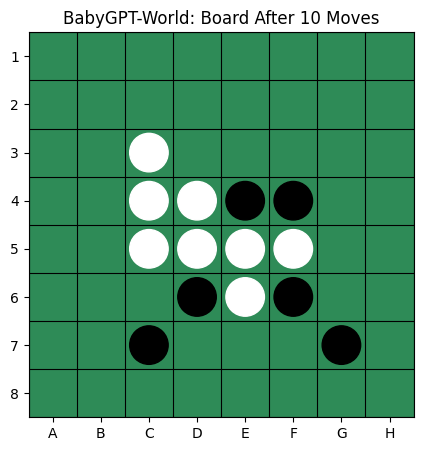

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# 0 = empty, 1 = black, -1 = white
board = np.zeros((8, 8), dtype=int)

# Starting Othello position
board[3, 3] = board[4, 4] = -1
board[3, 4] = board[4, 3] = 1

directions = [(r, c) for r in (-1, 0, 1)
                     for c in (-1, 0, 1) if (r, c) != (0, 0)]

# Replay the first 10 moves
for turn, token in enumerate(games[0][:10]):
    token = int(token)
    if token in (0, 65):
        continue

    row, col = divmod(token - 1, 8)
    player = 1 if turn % 2 == 0 else -1
    board[row, col] = player

    for dr, dc in directions:
        r, c = row + dr, col + dc
        captured = []

        while 0 <= r < 8 and 0 <= c < 8 and board[r, c] == -player:
            captured.append((r, c))
            r += dr
            c += dc

        if 0 <= r < 8 and 0 <= c < 8 and board[r, c] == player:
            for rr, cc in captured:
                board[rr, cc] = player

# Draw the board
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_facecolor("seagreen")
ax.set_xlim(-0.5, 7.5)
ax.set_ylim(7.5, -0.5)

for row in range(8):
    for col in range(8):
        if board[row, col] != 0:
            color = "black" if board[row, col] == 1 else "white"
            ax.add_patch(plt.Circle((col, row), 0.4, color=color))

ax.set_xticks(range(8), list("ABCDEFGH"))
ax.set_yticks(range(8), range(1, 9))
ax.set_xticks(np.arange(9) - 0.5, minor=True)
ax.set_yticks(np.arange(9) - 0.5, minor=True)
ax.grid(which="minor", color="black")
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_aspect("equal")

plt.title("BabyGPT-World: Board After 10 Moves")
plt.show()


In [14]:

import numpy as np

# Try loading 1,000 games instead of 100,000
games = dataset["seqs"].isel(game=slice(0, 1000)).values

# Create reproducible splits
rng = np.random.default_rng(42)
indices = rng.permutation(len(games))

train_games = games[indices[:800]]
val_games = games[indices[800:900]]
test_games = games[indices[900:]]

print("Training:", train_games.shape)
print("Validation:", val_games.shape)
print("Testing:", test_games.shape)


Training: (800, 60)
Validation: (100, 60)
Testing: (100, 60)


In [15]:

import torch

# Select 4 games, using 11 tokens from each
batch = torch.tensor(train_games[:4, :11], dtype=torch.long)

# Input = first 10 tokens
x = batch[:, :-1]

# Target = the following 10 tokens
y = batch[:, 1:]

# Ignore padding positions when computing loss later
valid_targets = y != 0

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nFirst game's input:", x[0].tolist())
print("First game's target:", y[0].tolist())

print("\nValid target positions:", valid_targets[0].tolist())


Input shape: torch.Size([4, 10])
Target shape: torch.Size([4, 10])

First game's input: [20, 35, 44, 19, 38, 46, 34, 51, 45, 26]
First game's target: [35, 44, 19, 38, 46, 34, 51, 45, 26, 58]

Valid target positions: [True, True, True, True, True, True, True, True, True, True]


In [16]:

import torch
import torch.nn as nn

# BabyGPT configuration
vocab_size = 66
embedding_dim = 256
context_length = 60

# Learnable token and position embeddings
token_embedding = nn.Embedding(vocab_size, embedding_dim)
position_embedding = nn.Embedding(context_length, embedding_dim)

# Use the input batch from Step 6
batch_size, sequence_length = x.shape

# Convert token IDs into vectors
token_vectors = token_embedding(x)

# Create position IDs: 0, 1, 2, ..., 9
positions = torch.arange(sequence_length)
position_vectors = position_embedding(positions)

# Combine token information and position information
embeddings = token_vectors + position_vectors

print("Input shape:", x.shape)
print("Token embeddings:", token_vectors.shape)
print("Position embeddings:", position_vectors.shape)
print("Final embeddings:", embeddings.shape)


Input shape: torch.Size([4, 10])
Token embeddings: torch.Size([4, 10, 256])
Position embeddings: torch.Size([10, 256])
Final embeddings: torch.Size([4, 10, 256])


Q shape: torch.Size([4, 10, 64])
Attention weights: torch.Size([4, 10, 10])
Output shape: torch.Size([4, 10, 64])
First game's attention weights:


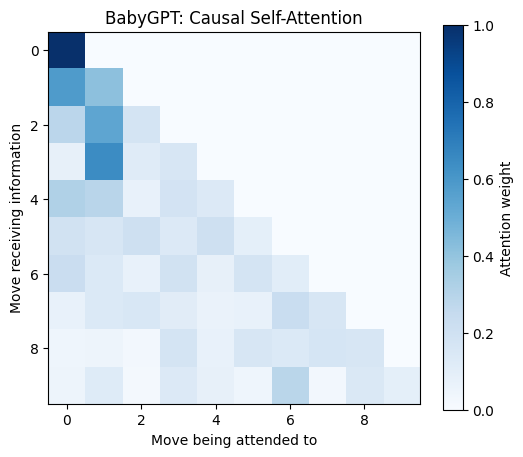

In [17]:

import math
import torch
import torch.nn as nn

# One attention head
head_size = 64

query = nn.Linear(embedding_dim, head_size, bias=False)
key = nn.Linear(embedding_dim, head_size, bias=False)
value = nn.Linear(embedding_dim, head_size, bias=False)

# Create Q, K, V from our embeddings
Q = query(embeddings)
K = key(embeddings)
V = value(embeddings)

# Calculate attention scores
scores = Q @ K.transpose(-2, -1)
scores = scores / math.sqrt(head_size)

# Prevent attention to future tokens
T = embeddings.shape[1]
mask = torch.tril(torch.ones(T, T, dtype=torch.bool))
scores = scores.masked_fill(~mask, float("-inf"))

# Convert scores into attention probabilities
weights = torch.softmax(scores, dim=-1)

# Combine information using the values
output = weights @ V

print("Q shape:", Q.shape)
print("Attention weights:", weights.shape)
print("Output shape:", output.shape)
print("First game's attention weights:")

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(weights[0].detach().numpy(), cmap="Blues")
plt.xlabel("Move being attended to")
plt.ylabel("Move receiving information")
plt.colorbar(label="Attention weight")
plt.title("BabyGPT: Causal Self-Attention")
plt.show()


In [18]:

import math
import torch
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, embedding_dim=256, num_heads=4):
        super().__init__()

        self.num_heads = num_heads
        self.head_size = embedding_dim // num_heads

        assert embedding_dim % num_heads == 0

        self.query = nn.Linear(embedding_dim, embedding_dim)
        self.key = nn.Linear(embedding_dim, embedding_dim)
        self.value = nn.Linear(embedding_dim, embedding_dim)

        self.projection = nn.Linear(embedding_dim, embedding_dim)

    def forward(self, x):
        B, T, C = x.shape

        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        # Divide 256 dimensions into 4 heads of 64
        Q = Q.reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)
        K = K.reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)
        V = V.reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)

        # Attention for all heads
        scores = Q @ K.transpose(-2, -1)
        scores = scores / math.sqrt(self.head_size)

        mask = torch.tril(torch.ones(T, T, device=x.device, dtype=torch.bool))
        scores = scores.masked_fill(~mask, float("-inf"))

        weights = torch.softmax(scores, dim=-1)
        output = weights @ V

        # Combine the heads
        output = output.transpose(1, 2).contiguous().reshape(B, T, C)

        return self.projection(output)


attention = MultiHeadAttention()
result = attention(embeddings)

print("Input shape:", embeddings.shape)
print("Output shape:", result.shape)
print("Number of parameters:", sum(p.numel() for p in attention.parameters()))


Input shape: torch.Size([4, 10, 256])
Output shape: torch.Size([4, 10, 256])
Number of parameters: 263168


In [19]:

import torch.nn as nn

class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim=256, num_heads=4):
        super().__init__()

        # Normalize before attention
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.attention = MultiHeadAttention(embedding_dim, num_heads)

        # Normalize before the feed-forward network
        self.norm2 = nn.LayerNorm(embedding_dim)

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim),
            nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim)
        )

    def forward(self, x):
        # Attention + residual connection
        x = x + self.attention(self.norm1(x))

        # Feed-forward network + residual connection
        x = x + self.mlp(self.norm2(x))

        return x


# Test our Transformer block
block = TransformerBlock()

output = block(embeddings)

print("Input shape:", embeddings.shape)
print("Output shape:", output.shape)
print("Parameters:", sum(p.numel() for p in block.parameters()))


Input shape: torch.Size([4, 10, 256])
Output shape: torch.Size([4, 10, 256])
Parameters: 789760


In [20]:

import torch
import torch.nn as nn

class BabyGPT(nn.Module):
    def __init__(self):
        super().__init__()

        # Convert token IDs and positions into vectors
        self.token_embedding = nn.Embedding(66, 256)
        self.position_embedding = nn.Embedding(60, 256)

        # Stack four Transformer blocks
        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(4)]
        )

        # Final normalization and prediction layer
        self.norm = nn.LayerNorm(256)
        self.lm_head = nn.Linear(256, 66)

    def forward(self, x):
        B, T = x.shape

        token_vectors = self.token_embedding(x)

        positions = torch.arange(T, device=x.device)
        position_vectors = self.position_embedding(positions)

        x = token_vectors + position_vectors
        x = self.blocks(x)
        x = self.norm(x)

        logits = self.lm_head(x)

        return logits


# Create our first complete GPT
model = BabyGPT()

# Test it using the batch from Step 6
logits = model(x)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Total parameters:", sum(p.numel() for p in model.parameters()))


Input shape: torch.Size([4, 10])
Output shape: torch.Size([4, 10, 66])
Total parameters: 3208770


Step 50: Loss = 0.0369
Step 100: Loss = 0.0359
Step 150: Loss = 0.0356
Step 200: Loss = 0.0353
Step 250: Loss = 0.0352
Step 300: Loss = 0.0351


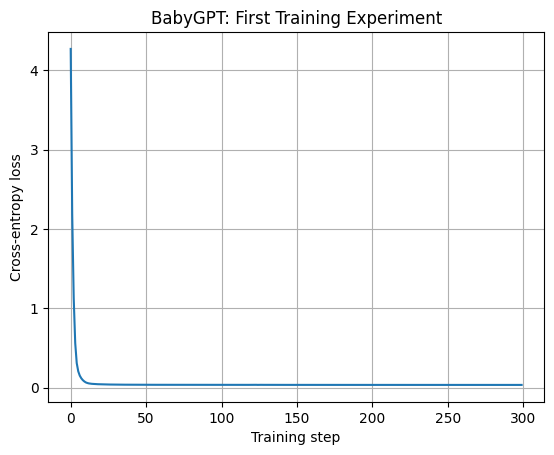

In [21]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Move our model and tiny batch to the GPU
model = model.to(device)
x = x.to(device)
y = y.to(device)

# AdamW updates the model's parameters
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

losses = []
model.train()

for step in range(300):
    # 1. Predict the next token
    logits = model(x)

    # 2. Measure prediction error (ignore padding)
    loss = F.cross_entropy(
        logits.reshape(-1, 66),
        y.reshape(-1),
        ignore_index=0
    )

    # 3. Calculate gradients
    optimizer.zero_grad()
    loss.backward()

    # 4. Update model parameters
    optimizer.step()

    losses.append(loss.item())

    if (step + 1) % 50 == 0:
        print(f"Step {step + 1}: Loss = {loss.item():.4f}")

# Plot our learning curve
plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("BabyGPT: First Training Experiment")
plt.grid(True)
plt.show()


Step 20: Train = 3.887, Val = 3.911
Step 40: Train = 3.805, Val = 3.836
Step 60: Train = 3.724, Val = 3.800
Step 80: Train = 3.619, Val = 3.768
Step 100: Train = 3.518, Val = 3.728


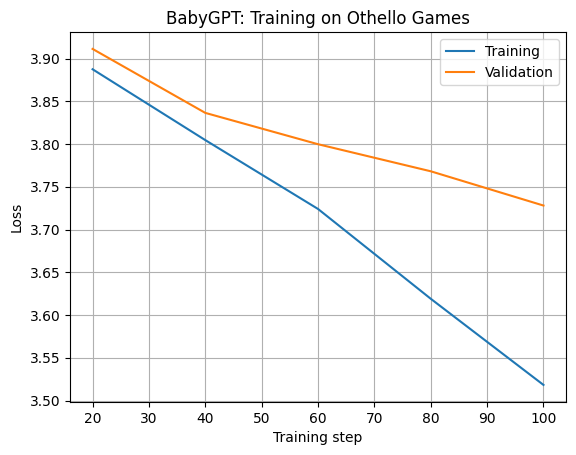

In [22]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Start with a fresh BabyGPT (not the memorized Step 12 model)
model = BabyGPT().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)

# Convert our datasets to tensors
train_data = torch.tensor(train_games, dtype=torch.long, device=device)
val_data = torch.tensor(val_games, dtype=torch.long, device=device)

train_losses = []
val_losses = []

for step in range(100):
    model.train()

    # Choose 32 random training games
    indices = torch.randint(len(train_data), (32,), device=device)
    batch = train_data[indices]

    x = batch[:, :-1]
    y = batch[:, 1:]

    # Predict, calculate loss, and update parameters
    logits = model(x)
    loss = F.cross_entropy(
        logits.reshape(-1, 66),
        y.reshape(-1),
        ignore_index=0
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Evaluate every 20 steps
    if (step + 1) % 20 == 0:
        model.eval()

        with torch.no_grad():
            val_x = val_data[:, :-1]
            val_y = val_data[:, 1:]

            val_logits = model(val_x)
            val_loss = F.cross_entropy(
                val_logits.reshape(-1, 66),
                val_y.reshape(-1),
                ignore_index=0
            )

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        print(f"Step {step+1}: Train = {loss.item():.3f}, Val = {val_loss.item():.3f}")

# Save the model
torch.save(model.state_dict(), "babygpt_step13.pt")

# Visualize training progress
steps = [20, 40, 60, 80, 100]
plt.plot(steps, train_losses, label="Training")
plt.plot(steps, val_losses, label="Validation")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("BabyGPT: Training on Othello Games")
plt.legend()
plt.grid(True)
plt.show()


Step 150: Train = 3.397, Val = 3.648
Step 200: Train = 3.150, Val = 3.572
Step 250: Train = 2.901, Val = 3.510
Step 300: Train = 2.520, Val = 3.519
Step 350: Train = 2.050, Val = 3.588
Step 400: Train = 1.653, Val = 3.734
Step 450: Train = 1.256, Val = 3.956
Step 500: Train = 1.226, Val = 4.145


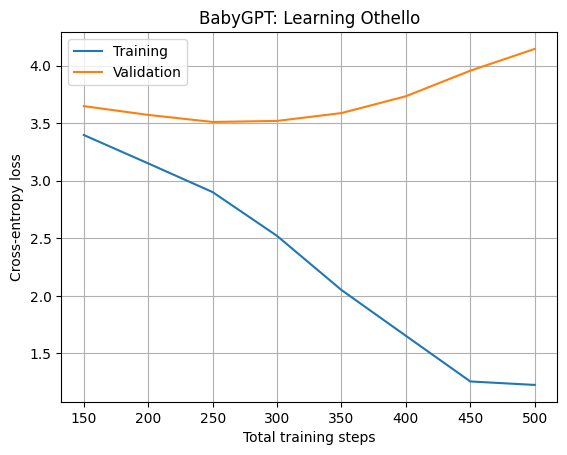

In [23]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Restore the model we trained in Step 13
model = BabyGPT().to(device)
model.load_state_dict(torch.load("babygpt_step13.pt", map_location=device))

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)

train_losses = []
val_losses = []
steps = []

# Continue training for 400 more updates
for step in range(1, 401):
    model.train()

    # Random batch of 32 games
    indices = torch.randint(len(train_data), (32,), device=device)
    batch = train_data[indices]

    x = batch[:, :-1]
    y = batch[:, 1:]

    logits = model(x)

    loss = F.cross_entropy(
        logits.reshape(-1, 66),
        y.reshape(-1),
        ignore_index=0
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Evaluate every 50 updates
    if step % 50 == 0:
        model.eval()

        with torch.no_grad():
            val_logits = model(val_data[:, :-1])
            val_loss = F.cross_entropy(
                val_logits.reshape(-1, 66),
                val_data[:, 1:].reshape(-1),
                ignore_index=0
            )

        steps.append(100 + step)
        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        print(
            f"Step {100 + step}: "
            f"Train = {loss.item():.3f}, "
            f"Val = {val_loss.item():.3f}"
        )

# Save the model and optimizer for later use
torch.save({
    "model": model.state_dict(),
    "optimizer": optimizer.state_dict(),
    "step": 500
}, "babygpt_step14.pt")

# Plot the learning curves
plt.plot(steps, train_losses, label="Training")
plt.plot(steps, val_losses, label="Validation")

plt.xlabel("Total training steps")
plt.ylabel("Cross-entropy loss")
plt.title("BabyGPT: Learning Othello")
plt.legend()
plt.grid(True)
plt.show()


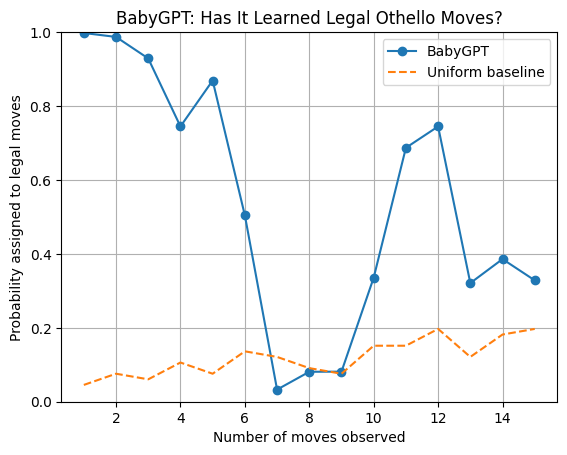

BabyGPT average legal mass: 0.535
Uniform baseline: 0.119


In [24]:

import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Start from the standard Othello board
board = np.zeros((8, 8), dtype=int)
board[3, 3] = board[4, 4] = -1
board[3, 4] = board[4, 3] = 1

directions = [(r, c) for r in (-1, 0, 1)
              for c in (-1, 0, 1) if (r, c) != (0, 0)]

# Find pieces captured by a move
def get_flips(board, row, col, player):
    if board[row, col] != 0:
        return []

    flips = []

    for dr, dc in directions:
        r, c = row + dr, col + dc
        line = []

        while 0 <= r < 8 and 0 <= c < 8 and board[r, c] == -player:
            line.append((r, c))
            r += dr
            c += dc

        if 0 <= r < 8 and 0 <= c < 8 and board[r, c] == player:
            flips.extend(line)

    return flips

# Find all legal moves as token IDs
def legal_moves(board, player):
    moves = []

    for token in range(1, 65):
        row, col = divmod(token - 1, 8)

        if get_flips(board, row, col, player):
            moves.append(token)

    return moves if moves else [65]  # Pass when no moves exist


# 2. Load a game BabyGPT hasn't trained on
game = test_games[0]
tokens = torch.tensor(game[:16], dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    probabilities = torch.softmax(model(tokens[:-1].unsqueeze(0))[0], dim=-1)

# 3. Replay the game and evaluate each prediction
player = 1  # Black moves first
legal_scores = []
random_scores = []

for turn in range(15):
    token = int(game[turn])

    legal = legal_moves(board, player)
    assert token in legal, f"Invalid move at turn {turn + 1}: {token}"

    # Update the board
    if token != 65:
        row, col = divmod(token - 1, 8)
        flips = get_flips(board, row, col, player)

        board[row, col] = player
        for r, c in flips:
            board[r, c] = player

    player = -player

    # Evaluate next-move predictions
    next_legal = legal_moves(board, player)
    legal_scores.append(probabilities[turn, next_legal].sum().item())
    random_scores.append(len(next_legal) / 66)

# 4. Visualize the result
plt.plot(range(1, 16), legal_scores, marker="o", label="BabyGPT")
plt.plot(range(1, 16), random_scores, linestyle="--", label="Uniform baseline")
plt.xlabel("Number of moves observed")
plt.ylabel("Probability assigned to legal moves")
plt.title("BabyGPT: Has It Learned Legal Othello Moves?")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

print(f"BabyGPT average legal mass: {np.mean(legal_scores):.3f}")
print(f"Uniform baseline: {np.mean(random_scores):.3f}")


100 steps: Average legal mass = 0.383
500 steps: Average legal mass = 0.535


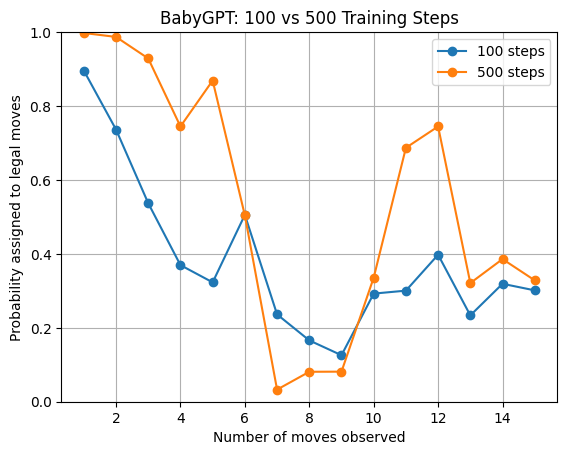

In [25]:

import torch
import numpy as np
import matplotlib.pyplot as plt

# Load our two saved models
model_100 = BabyGPT().to(device)
model_100.load_state_dict(
    torch.load("babygpt_step13.pt", map_location=device)
)

model_500 = BabyGPT().to(device)
checkpoint = torch.load("babygpt_step14.pt", map_location=device)
model_500.load_state_dict(checkpoint["model"])

model_100.eval()
model_500.eval()

# Reconstruct legal moves after each of the first 15 moves
board = np.zeros((8, 8), dtype=int)
board[3, 3] = board[4, 4] = -1
board[3, 4] = board[4, 3] = 1

game = test_games[0]
player = 1
legal_targets = []

for turn in range(15):
    token = int(game[turn])
    legal = legal_moves(board, player)

    assert token in legal, f"Invalid move at turn {turn + 1}"

    if token != 65:
        row, col = divmod(token - 1, 8)
        flips = get_flips(board, row, col, player)

        board[row, col] = player
        for r, c in flips:
            board[r, c] = player

    player = -player
    legal_targets.append(legal_moves(board, player))

# Evaluate both checkpoints
scores = {}

with torch.no_grad():
    tokens = torch.tensor(game[:15], device=device).unsqueeze(0)

    for name, current_model in [
        ("100 steps", model_100),
        ("500 steps", model_500)
    ]:
        probabilities = torch.softmax(current_model(tokens)[0], dim=-1)

        scores[name] = [
            probabilities[i, legal_targets[i]].sum().item()
            for i in range(15)
        ]

# Compare the results
for name, values in scores.items():
    print(f"{name}: Average legal mass = {np.mean(values):.3f}")
    plt.plot(range(1, 16), values, marker="o", label=name)

plt.xlabel("Number of moves observed")
plt.ylabel("Probability assigned to legal moves")
plt.title("BabyGPT: 100 vs 500 Training Steps")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


Layer 1: torch.Size([1, 15, 256])
Layer 2: torch.Size([1, 15, 256])
Layer 3: torch.Size([1, 15, 256])
Layer 4: torch.Size([1, 15, 256])


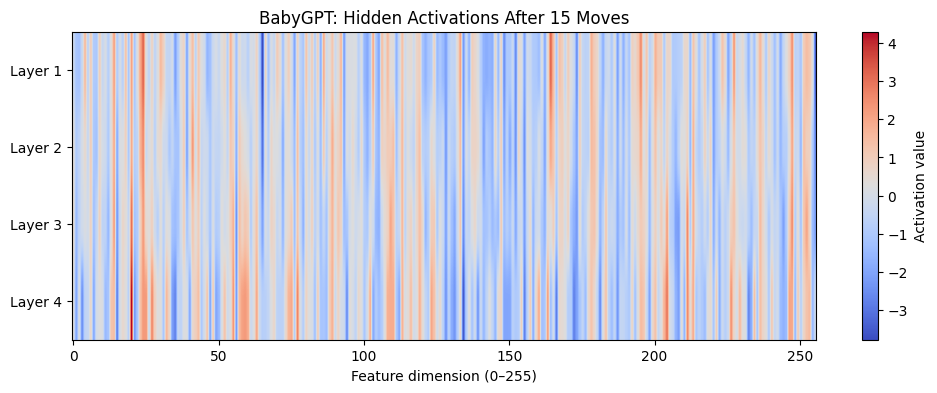

In [26]:

import torch
import matplotlib.pyplot as plt

# Use our trained BabyGPT from Step 14
model.eval()

# Store the output of each Transformer layer
activations = []

def save_activation(module, inputs, output):
    activations.append(output.detach().cpu())

# Attach a hook to each of the four Transformer blocks
hooks = []

for block in model.blocks:
    hook = block.register_forward_hook(save_activation)
    hooks.append(hook)

# Give BabyGPT 15 moves from an unseen game
tokens = torch.tensor(
    test_games[0][:15],
    dtype=torch.long,
    device=device
).unsqueeze(0)

with torch.no_grad():
    model(tokens)

# Remove hooks after collecting the activations
for hook in hooks:
    hook.remove()

# Inspect the shapes
for i, activation in enumerate(activations):
    print(f"Layer {i + 1}: {activation.shape}")

# Visualize the final position's 256 features in each layer
features = torch.stack([a[0, -1] for a in activations])

plt.figure(figsize=(12, 4))
plt.imshow(features.numpy(), aspect="auto", cmap="coolwarm")
plt.colorbar(label="Activation value")
plt.yticks(range(4), [f"Layer {i}" for i in range(1, 5)])
plt.xlabel("Feature dimension (0–255)")
plt.title("BabyGPT: Hidden Activations After 15 Moves")
plt.show()


In [28]:

import numpy as np
from pathlib import Path

# Create a folder for our local training data
data_folder = Path("babygpt_data")
data_folder.mkdir(exist_ok=True)

# Download one complete chunk: 12,500 games
chunk = dataset["seqs"].isel(game=slice(0, 12_500)).values

# Verify token IDs before converting to uint8
assert chunk.min() >= 0 and chunk.max() <= 65

# Save it locally
file_path = data_folder / "classic_0000.npy"
np.save(file_path, chunk.astype(np.uint8))

print("Saved:", file_path)
print("Games:", chunk.shape[0])
print("File size:", round(file_path.stat().st_size / 1024**2, 2), "MiB")


Saved: babygpt_data/classic_0000.npy
Games: 12500
File size: 0.72 MiB


In [29]:

import numpy as np
from pathlib import Path

data_folder = Path("babygpt_data")
data_folder.mkdir(exist_ok=True)

chunk_size = 12_500
total_chunks = 80  # First milestone: 1 million games

for i in range(total_chunks):
    file_path = data_folder / f"classic_{i:04d}.npy"

    # Skip chunks that have already been saved
    if file_path.exists():
        continue

    start = i * chunk_size
    end = start + chunk_size

    try:
        chunk = dataset["seqs"].isel(game=slice(start, end)).values

        assert chunk.shape == (chunk_size, 60)
        assert chunk.min() >= 0 and chunk.max() <= 65

        # Save safely: write to a temporary file first
        temporary = file_path.with_suffix(".tmp")
        with open(temporary, "wb") as f:
            np.save(f, chunk.astype(np.uint8))

        temporary.replace(file_path)

        print(f"Saved chunk {i + 1}/{total_chunks}")

    except Exception as error:
        print(f"Stopped at chunk {i}: {error}")
        break

saved_chunks = len(list(data_folder.glob("classic_*.npy")))
print(f"\nDownloaded: {saved_chunks * chunk_size:,} games")


Saved chunk 2/80
Saved chunk 3/80
Saved chunk 4/80
Saved chunk 5/80
Saved chunk 6/80
Saved chunk 7/80
Saved chunk 8/80
Saved chunk 9/80
Saved chunk 10/80
Saved chunk 11/80
Saved chunk 12/80
Saved chunk 13/80
Saved chunk 14/80
Saved chunk 15/80
Saved chunk 16/80
Saved chunk 17/80
Saved chunk 18/80
Saved chunk 19/80
Saved chunk 20/80
Saved chunk 21/80
Saved chunk 22/80
Saved chunk 23/80
Saved chunk 24/80
Saved chunk 25/80
Saved chunk 26/80
Saved chunk 27/80
Saved chunk 28/80
Saved chunk 29/80
Saved chunk 30/80
Saved chunk 31/80
Saved chunk 32/80
Saved chunk 33/80
Saved chunk 34/80
Saved chunk 35/80
Saved chunk 36/80
Saved chunk 37/80
Saved chunk 38/80
Saved chunk 39/80
Saved chunk 40/80
Saved chunk 41/80
Saved chunk 42/80
Saved chunk 43/80
Saved chunk 44/80
Saved chunk 45/80
Saved chunk 46/80
Saved chunk 47/80
Saved chunk 48/80
Saved chunk 49/80
Saved chunk 50/80
Saved chunk 51/80
Saved chunk 52/80
Saved chunk 53/80
Saved chunk 54/80
Saved chunk 55/80
Saved chunk 56/80
Saved chunk 57/80


In [30]:

import numpy as np
from pathlib import Path

# Find our 80 downloaded files
files = sorted(Path("babygpt_data").glob("classic_*.npy"))

assert len(files) == 80, "Expected 80 dataset files"

# Load and combine the games
games_large = np.concatenate([np.load(file) for file in files])

# Check that everything is correct
assert games_large.shape == (1_000_000, 60)
assert games_large.min() >= 0
assert games_large.max() <= 65

print("Games:", games_large.shape[0])
print("Moves per game:", games_large.shape[1])
print("Data type:", games_large.dtype)
print("Memory usage:", round(games_large.nbytes / 1024**2, 2), "MiB")
print("First 10 tokens:", games_large[0, :10])


Games: 1000000
Moves per game: 60
Data type: uint8
Memory usage: 57.22 MiB
First 10 tokens: [45 44 27 46 51 19 30 35 55 38]


In [31]:

import numpy as np

# Remove identical game sequences
unique_games = np.unique(games_large, axis=0)

print("Original games:", len(games_large))
print("Unique games:", len(unique_games))

# Shuffle reproducibly
rng = np.random.default_rng(42)
rng.shuffle(unique_games)

# Split by percentages
n = len(unique_games)
train_end = int(n * 0.98)
val_end = int(n * 0.99)

train_large = unique_games[:train_end]
val_large = unique_games[train_end:val_end]
test_large = unique_games[val_end:]

print("Training:", train_large.shape)
print("Validation:", val_large.shape)
print("Testing:", test_large.shape)


Original games: 1000000
Unique games: 1000000
Training: (980000, 60)
Validation: (10000, 60)
Testing: (10000, 60)


In [32]:

import numpy as np
from pathlib import Path

data_folder = Path("babygpt_data")
chunk_size = 12_500
total_chunks = 1600

for i in range(total_chunks):
    file_path = data_folder / f"classic_{i:04d}.npy"

    # Skip existing valid chunks
    if file_path.exists():
        saved = np.load(file_path, mmap_mode="r")
        if saved.shape == (chunk_size, 60) and saved.dtype == np.uint8:
            continue

    # Download the next chunk
    try:
        start = i * chunk_size
        end = start + chunk_size

        chunk = dataset["seqs"].isel(game=slice(start, end)).values

        assert chunk.shape == (chunk_size, 60)
        assert chunk.min() >= 0 and chunk.max() <= 65

        # Save safely
        temporary = file_path.with_suffix(".tmp")

        with open(temporary, "wb") as f:
            np.save(f, chunk.astype(np.uint8))

        temporary.replace(file_path)

        if (i + 1) % 20 == 0:
            print(f"Downloaded {i + 1}/{total_chunks} chunks")

    except Exception as error:
        print(f"Stopped at chunk {i}: {error}")
        break

saved_chunks = len(list(data_folder.glob("classic_*.npy")))

print(f"\nSaved chunks: {saved_chunks}/{total_chunks}")
print(f"Saved games: {saved_chunks * chunk_size:,}")


Downloaded 100/1600 chunks
Downloaded 120/1600 chunks
Downloaded 140/1600 chunks
Downloaded 160/1600 chunks
Downloaded 180/1600 chunks
Downloaded 200/1600 chunks
Downloaded 220/1600 chunks
Downloaded 240/1600 chunks
Downloaded 260/1600 chunks
Downloaded 280/1600 chunks
Downloaded 300/1600 chunks
Downloaded 320/1600 chunks
Downloaded 340/1600 chunks
Downloaded 360/1600 chunks
Downloaded 380/1600 chunks
Downloaded 400/1600 chunks
Downloaded 420/1600 chunks
Downloaded 440/1600 chunks
Downloaded 460/1600 chunks
Downloaded 480/1600 chunks
Downloaded 500/1600 chunks
Downloaded 520/1600 chunks
Downloaded 540/1600 chunks
Downloaded 560/1600 chunks
Downloaded 580/1600 chunks
Downloaded 600/1600 chunks
Downloaded 620/1600 chunks
Downloaded 640/1600 chunks
Downloaded 660/1600 chunks
Downloaded 680/1600 chunks
Downloaded 700/1600 chunks
Downloaded 720/1600 chunks
Downloaded 740/1600 chunks
Downloaded 760/1600 chunks
Downloaded 780/1600 chunks
Downloaded 800/1600 chunks
Downloaded 820/1600 chunks
D

In [33]:

import numpy as np
from pathlib import Path

data_folder = Path("babygpt_data")

# Verify all 1,600 downloaded files
for i in range(1600):
    path = data_folder / f"classic_{i:04d}.npy"

    games = np.load(path, mmap_mode="r")

    assert games.shape == (12500, 60)
    assert games.dtype == np.uint8
    assert games.min() >= 0 and games.max() <= 65

# Reserve the first two chunks for evaluation
val_games_full = np.load(data_folder / "classic_0000.npy")
test_games_full = np.load(data_folder / "classic_0001.npy")

print("All 1,600 chunks verified!")
print("Training games:", 1598 * 12500)
print("Validation games:", len(val_games_full))
print("Test games:", len(test_games_full))


All 1,600 chunks verified!
Training games: 19975000
Validation games: 12500
Test games: 12500


In [34]:

import torch
import torch.nn.functional as F
import time

# Same attention dimensions as BabyGPT
batch_size = 256
num_heads = 4
seq_len = 60
head_size = 64

# Create random Q, K, V tensors on the GPU
shape = (batch_size, num_heads, seq_len, head_size)

Q = torch.randn(shape, device="cuda")
K = torch.randn(shape, device="cuda")
V = torch.randn(shape, device="cuda")

# Our original manual attention
def manual_attention():
    scores = Q @ K.transpose(-2, -1) / (head_size ** 0.5)
    mask = torch.tril(torch.ones(seq_len, seq_len, device="cuda")).bool()
    scores = scores.masked_fill(~mask, float("-inf"))
    return torch.softmax(scores, dim=-1) @ V

# PyTorch's optimized attention
def optimized_attention():
    return F.scaled_dot_product_attention(Q, K, V, is_causal=True)

# Check that both implementations agree
difference = (manual_attention() - optimized_attention()).abs().max()
print("Maximum output difference:", difference.item())

# Benchmark each implementation
for name, function in [
    ("Manual", manual_attention),
    ("Optimized SDPA", optimized_attention)
]:
    for _ in range(10):
        function()

    torch.cuda.synchronize()
    start = time.perf_counter()

    for _ in range(100):
        function()

    torch.cuda.synchronize()
    elapsed = (time.perf_counter() - start) / 100

    print(f"{name}: {elapsed * 1000:.3f} ms per forward pass")


Maximum output difference: 0.002398774027824402
Manual: 0.342 ms per forward pass
Optimized SDPA: 0.188 ms per forward pass


In [35]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadAttention(nn.Module):
    def __init__(self, embedding_dim=256, num_heads=4):
        super().__init__()

        self.num_heads = num_heads
        self.head_size = embedding_dim // num_heads

        self.query = nn.Linear(embedding_dim, embedding_dim)
        self.key = nn.Linear(embedding_dim, embedding_dim)
        self.value = nn.Linear(embedding_dim, embedding_dim)
        self.projection = nn.Linear(embedding_dim, embedding_dim)

    def forward(self, x):
        B, T, C = x.shape

        Q = self.query(x).reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)
        K = self.key(x).reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)
        V = self.value(x).reshape(B, T, self.num_heads, self.head_size).transpose(1, 2)

        # Optimized causal attention
        output = F.scaled_dot_product_attention(Q, K, V, is_causal=True)

        # Combine attention heads
        output = output.transpose(1, 2).contiguous().reshape(B, T, C)

        return self.projection(output)


# Rebuild the Transformer block and BabyGPT
# so the new attention implementation is used.
class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim=256, num_heads=4):
        super().__init__()

        self.norm1 = nn.LayerNorm(embedding_dim)
        self.attention = MultiHeadAttention(embedding_dim, num_heads)
        self.norm2 = nn.LayerNorm(embedding_dim)

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim),
            nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim)
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


# BabyGPT will now use the optimized TransformerBlock.
model = BabyGPT().to(device)

print("Optimized BabyGPT ready!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("BF16 supported:", torch.cuda.is_bf16_supported())


Optimized BabyGPT ready!
Parameters: 3208770
BF16 supported: True


In [37]:

import time
import torch
import torch.nn.functional as F

# Fresh model for this speed test
model = BabyGPT().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

# Use a sample of our local dataset
batch = torch.tensor(
    games_large[:256],
    dtype=torch.long,
    device=device
)

x = batch[:, :-1]
y = batch[:, 1:]

# Warm up the GPU
for step in range(5):
    optimizer.zero_grad()

    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits = model(x)
        loss = F.cross_entropy(
            logits.reshape(-1, 66),
            y.reshape(-1),
            ignore_index=0
        )

    loss.backward()
    optimizer.step()

# Measure 30 training updates
torch.cuda.synchronize()
start = time.perf_counter()

for step in range(30):
    optimizer.zero_grad()

    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits = model(x)
        loss = F.cross_entropy(
            logits.reshape(-1, 66),
            y.reshape(-1),
            ignore_index=0
        )

    loss.backward()
    optimizer.step()

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

print(f"Average step time: {elapsed / 30:.4f} seconds")
print(f"Tokens per second: {30 * x.numel() / elapsed:,.0f}")
print(f"Final loss: {loss.item():.4f}")


Average step time: 0.0161 seconds
Tokens per second: 938,103
Final loss: 3.4444


In [39]:

import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

torch.manual_seed(42)

data_dir = Path("babygpt_data")
save_dir = Path("babygpt_checkpoints")
save_dir.mkdir(exist_ok=True)

batch_size = 256
milestones = {80: "1M", 800: "10M", 1598: "20M"}

# Start BabyGPT from random weights
model = BabyGPT().to("cuda")
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

start_chunk = 2

# Resume if a checkpoint exists
resume_file = save_dir / "latest.pt"

if resume_file.exists():
    checkpoint = torch.load(
        resume_file, map_location="cuda", weights_only=False
    )
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    start_chunk = checkpoint["next_chunk"]
    print("Resuming from chunk:", start_chunk)


# Fixed validation data
val_data = torch.tensor(
    val_games_full, dtype=torch.long, device="cuda"
)


def validate():
    model.eval()
    total_loss = 0
    total_tokens = 0

    with torch.no_grad():
        for start in range(0, len(val_data), batch_size):
            batch = val_data[start:start + batch_size]
            x, y = batch[:, :-1], batch[:, 1:]

            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits = model(x)
                loss = F.cross_entropy(
                    logits.reshape(-1, 66),
                    y.reshape(-1),
                    ignore_index=0,
                    reduction="sum"
                )

            total_loss += loss.item()
            total_tokens += (y != 0).sum().item()

    return total_loss / total_tokens


# Train through all 1,598 training chunks
for chunk_id in range(start_chunk, 1600):

    games = np.load(
        data_dir / f"classic_{chunk_id:04d}.npy"
    )

    # Reproducible shuffle for each chunk
    rng = np.random.default_rng(42 + chunk_id)
    rng.shuffle(games)

    model.train()

    for start in range(0, len(games), batch_size):
        batch = torch.tensor(
            games[start:start + batch_size],
            dtype=torch.long,
            device="cuda"
        )

        x, y = batch[:, :-1], batch[:, 1:]

        optimizer.zero_grad()

        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(x)
            loss = F.cross_entropy(
                logits.reshape(-1, 66),
                y.reshape(-1),
                ignore_index=0
            )

        loss.backward()
        optimizer.step()

    completed = chunk_id - 1
    is_milestone = completed in milestones

    # Validate every 20 chunks and at milestones
    if completed % 20 == 0 or is_milestone:
        val_loss = validate()

        print(
            f"Games: {completed * 12500:,} | "
            f"Validation loss: {val_loss:.4f}",
            flush=True
        )

    # Save progress regularly
    if completed % 20 == 0 or is_milestone:
        state = {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "next_chunk": chunk_id + 1
        }

        temp_file = save_dir / "latest.tmp"
        torch.save(state, temp_file)
        temp_file.replace(resume_file)

        if is_milestone:
            name = milestones[completed]
            torch.save(
                state, save_dir / f"babygpt_{name}.pt"
            )
            print(f"Saved {name} checkpoint!")

print("BabyGPT training complete!")


Games: 250,000 | Validation loss: 2.6132
Games: 500,000 | Validation loss: 2.5332
Games: 750,000 | Validation loss: 2.4923
Games: 1,000,000 | Validation loss: 2.4673
Saved 1M checkpoint!
Games: 1,250,000 | Validation loss: 2.4407
Games: 1,500,000 | Validation loss: 2.4203
Games: 1,750,000 | Validation loss: 2.4049
Games: 2,000,000 | Validation loss: 2.3898
Games: 2,250,000 | Validation loss: 2.3784
Games: 2,500,000 | Validation loss: 2.3640
Games: 2,750,000 | Validation loss: 2.3532
Games: 3,000,000 | Validation loss: 2.3444
Games: 3,250,000 | Validation loss: 2.3342
Games: 3,500,000 | Validation loss: 2.3263
Games: 3,750,000 | Validation loss: 2.3186
Games: 4,000,000 | Validation loss: 2.3103
Games: 4,250,000 | Validation loss: 2.3032
Games: 4,500,000 | Validation loss: 2.2979
Games: 4,750,000 | Validation loss: 2.2920
Games: 5,000,000 | Validation loss: 2.2854
Games: 5,250,000 | Validation loss: 2.2801
Games: 5,500,000 | Validation loss: 2.2745
Games: 5,750,000 | Validation loss: 2.2

In [40]:

import numpy as np

def replay_game(game):
    board = np.zeros((8, 8), dtype=np.int8)

    # Standard starting position
    board[3, 3] = board[4, 4] = -1
    board[3, 4] = board[4, 3] = 1

    player = 1
    states = []

    for token in game:
        token = int(token)

        if token == 0:  # Padding
            break

        legal = legal_moves(board, player)
        assert token in legal, f"Illegal move: {token}"

        if token != 65:  # Not a pass
            row, col = divmod(token - 1, 8)
            flips = get_flips(board, row, col, player)

            board[row, col] = player

            for r, c in flips:
                board[r, c] = player

        # Store the board after this move
        states.append(board.copy())

        player = -player

    return np.array(states)


# Test our replay on 100 held-out games
boards = [replay_game(game) for game in test_games_full[:100]]

print("Games replayed:", len(boards))
print("First game board states:", boards[0].shape)
print("First game's final board:")
print(boards[0][-1])


Games replayed: 100
First game board states: (60, 8, 8)
First game's final board:
[[ 1 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1 -1 -1  1 -1  1 -1]
 [ 1 -1  1  1 -1  1  1  1]
 [ 1 -1  1  1 -1 -1  1  1]
 [ 1  1  1 -1 -1 -1  1  1]
 [ 1  1 -1 -1 -1  1  1  1]
 [ 1 -1  1 -1  1  1  1  1]
 [-1 -1 -1 -1  1  1  1  1]]


1M torch.Size([60, 256])
10M torch.Size([60, 256])
20M torch.Size([60, 256])


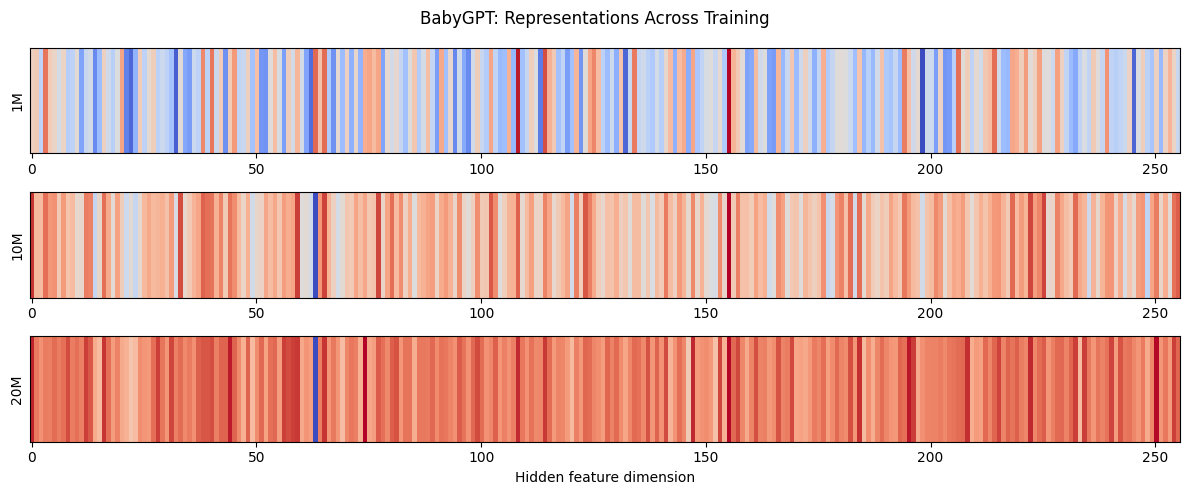

In [41]:

import torch
import matplotlib.pyplot as plt

# One held-out game, shared by all checkpoints
tokens = torch.tensor(
    test_games_full[0],
    dtype=torch.long,
    device=device
).unsqueeze(0)

representations = {}

for name in ["1M", "10M", "20M"]:
    checkpoint = torch.load(
        f"babygpt_checkpoints/babygpt_{name}.pt",
        map_location=device,
        weights_only=False
    )

    model = BabyGPT().to(device)
    model.load_state_dict(checkpoint["model"])
    model.eval()

    # Capture the final Transformer block's output
    captured = []

    hook = model.blocks[-1].register_forward_hook(
        lambda module, inputs, output: captured.append(output.detach())
    )

    with torch.no_grad():
        model(tokens)

    hook.remove()

    # Shape: (60 moves, 256 features)
    representations[name] = captured[0][0].cpu()

    print(name, representations[name].shape)

# Compare representations after the last move
fig, axes = plt.subplots(3, 1, figsize=(12, 5))

for ax, name in zip(axes, representations):
    vector = representations[name][-1].unsqueeze(0)

    ax.imshow(vector.numpy(), aspect="auto", cmap="coolwarm")
    ax.set_ylabel(name)
    ax.set_yticks([])

axes[-1].set_xlabel("Hidden feature dimension")
plt.suptitle("BabyGPT: Representations Across Training")
plt.tight_layout()
plt.show()


In [42]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Load the fully trained BabyGPT
checkpoint = torch.load(
    "babygpt_checkpoints/babygpt_20M.pt",
    map_location=device,
    weights_only=False
)

model = BabyGPT().to(device)
model.load_state_dict(checkpoint["model"])
model.eval()

# Get final-layer activations for a collection of games
def get_features(games):
    tokens = torch.tensor(games, dtype=torch.long, device=device)
    saved = []

    hook = model.blocks[-1].register_forward_hook(
        lambda module, inputs, output: saved.append(output.detach())
    )

    with torch.no_grad():
        model(tokens)

    hook.remove()
    return saved[0].cpu()


# 100 games for probe training, 100 for evaluation
probe_train_games = np.load("babygpt_data/classic_0002.npy")[:100]
probe_test_games = test_games_full[:100]

train_features = get_features(probe_train_games)
test_features = get_features(probe_test_games)

# Ground-truth boards, aligned with every move position
train_boards = np.array([replay_game(g) for g in probe_train_games])
test_boards = np.array([replay_game(g) for g in probe_test_games])

# -1, 0, 1 become class labels 0, 1, 2
train_labels = torch.tensor(train_boards.reshape(-1, 64) + 1, dtype=torch.long)
test_labels = torch.tensor(test_boards.reshape(-1, 64) + 1, dtype=torch.long)

# Flatten games and positions: (100 * 60, 256)
X_train = train_features.reshape(-1, 256).to(device)
X_test = test_features.reshape(-1, 256).to(device)
Y_train = train_labels.to(device)
Y_test = test_labels.to(device)

# Our linear board-state probe
probe = nn.Linear(256, 64 * 3).to(device)
optimizer = torch.optim.AdamW(probe.parameters(), lr=0.001)

for epoch in range(100):
    logits = probe(X_train).reshape(-1, 64, 3)

    loss = F.cross_entropy(
        logits.reshape(-1, 3),
        Y_train.reshape(-1)
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Evaluate on unseen probe-test games
with torch.no_grad():
    predictions = probe(X_test).reshape(-1, 64, 3).argmax(dim=-1)
    accuracy = (predictions == Y_test).float().mean().item()

print(f"Board-square reconstruction accuracy: {accuracy:.2%}")


Board-square reconstruction accuracy: 70.84%


In [43]:

import torch

# Predictions from our trained linear probe
probe.eval()

with torch.no_grad():
    predictions = probe(X_test).reshape(-1, 64, 3).argmax(dim=-1)

# Overall board-square accuracy
accuracy = (predictions == Y_test).float().mean().item()

# Baseline: predict EMPTY for every square
# Labels: 0 = white, 1 = empty, 2 = black
empty_baseline = (Y_test == 1).float().mean().item()

# Accuracy separately for each square state
for label, name in [(0, "White"), (1, "Empty"), (2, "Black")]:
    mask = Y_test == label
    class_accuracy = (predictions[mask] == label).float().mean().item()
    print(f"{name} accuracy: {class_accuracy:.2%}")

# Entire board must be correct
complete_boards = (predictions == Y_test).all(dim=1)
board_accuracy = complete_boards.float().mean().item()

print()
print(f"BabyGPT probe accuracy: {accuracy:.2%}")
print(f"Always-empty baseline: {empty_baseline:.2%}")
print(f"Perfectly reconstructed boards: {board_accuracy:.2%}")


White accuracy: 49.02%
Empty accuracy: 95.90%
Black accuracy: 49.75%

BabyGPT probe accuracy: 70.84%
Always-empty baseline: 46.11%
Perfectly reconstructed boards: 3.65%


Random: 62.31%
1M: 73.17%
10M: 71.35%
20M: 70.97%


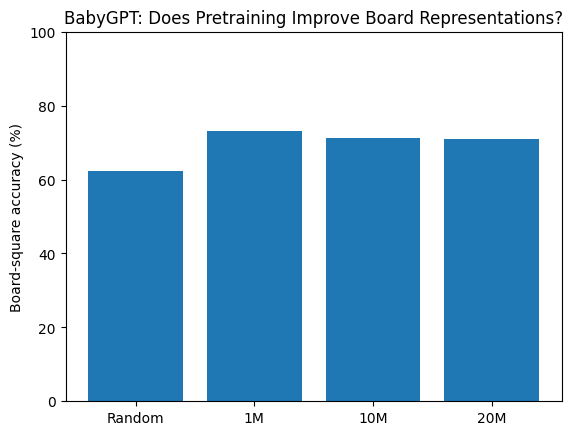

In [44]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

results = {}

for name in ["Random", "1M", "10M", "20M"]:

    # Start from the same random initialization
    torch.manual_seed(42)
    model = BabyGPT().to(device)

    if name != "Random":
        checkpoint = torch.load(
            f"babygpt_checkpoints/babygpt_{name}.pt",
            map_location=device,
            weights_only=False
        )
        model.load_state_dict(checkpoint["model"])

    model.eval()

    # Extract hidden representations
    X_train = get_features(probe_train_games).reshape(-1, 256).to(device)
    X_test = get_features(probe_test_games).reshape(-1, 256).to(device)

    # Train the same linear probe
    torch.manual_seed(42)
    probe = nn.Linear(256, 64 * 3).to(device)
    optimizer = torch.optim.AdamW(probe.parameters(), lr=0.001)

    for epoch in range(100):
        logits = probe(X_train).reshape(-1, 64, 3)

        loss = F.cross_entropy(
            logits.reshape(-1, 3),
            Y_train.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Evaluate on held-out boards
    with torch.no_grad():
        predictions = probe(X_test).reshape(-1, 64, 3).argmax(-1)

        accuracy = (predictions == Y_test).float().mean().item()

    results[name] = accuracy
    print(f"{name}: {accuracy:.2%}")

# Visualize the comparison
plt.bar(results.keys(), [v * 100 for v in results.values()])
plt.ylabel("Board-square accuracy (%)")
plt.title("BabyGPT: Does Pretraining Improve Board Representations?")
plt.ylim(0, 100)
plt.show()


In [45]:
    
import numpy as np
import torch
from pathlib import Path

folder = Path("babygpt_features")
folder.mkdir(exist_ok=True)

# Fixed games for our probing experiments
game_sets = {
    "train": np.load("babygpt_data/classic_0002.npy")[100:1100],
    "val": np.load("babygpt_data/classic_0000.npy")[:250],
    "test": np.load("babygpt_data/classic_0001.npy")[100:600]
}

# History lengths to inspect (1 through 59)
positions = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 59])

for name in ["Random", "1M", "10M", "20M"]:
    torch.manual_seed(42)
    model = BabyGPT().to(device)

    if name != "Random":
        checkpoint = torch.load(
            f"babygpt_checkpoints/babygpt_{name}.pt",
            map_location=device,
            weights_only=False
        )
        model.load_state_dict(checkpoint["model"])

    model.eval()

    for split, games in game_sets.items():
        all_features = []

        # Process 64 games at a time
        for start in range(0, len(games), 64):
            batch = torch.tensor(
                games[start:start + 64, :59],
                dtype=torch.long,
                device=device
            )

            captured = []
            hooks = [
                block.register_forward_hook(
                    lambda module, inputs, output: captured.append(output.detach())
                )
                for block in model.blocks
            ]

            with torch.no_grad():
                model(batch)

            for hook in hooks:
                hook.remove()

            # Shape: games × layers × positions × features
            features = torch.stack(captured, dim=1)
            features = features[:, :, positions - 1, :]

            all_features.append(features.cpu().numpy())

        all_features = np.concatenate(all_features)

        np.save(folder / f"{name}_{split}.npy", all_features)

        print(name, split, all_features.shape)

print("Feature extraction complete!")


Random train (1000, 4, 12, 256)
Random val (250, 4, 12, 256)
Random test (500, 4, 12, 256)
1M train (1000, 4, 12, 256)
1M val (250, 4, 12, 256)
1M test (500, 4, 12, 256)
10M train (1000, 4, 12, 256)
10M val (250, 4, 12, 256)
10M test (500, 4, 12, 256)
20M train (1000, 4, 12, 256)
20M val (250, 4, 12, 256)
20M test (500, 4, 12, 256)
Feature extraction complete!


In [46]:

import numpy as np
from pathlib import Path

folder = Path("babygpt_features")

positions = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 59])

for split, games in game_sets.items():
    absolute_labels = []
    relative_labels = []

    for game in games:
        states = replay_game(game)

        # Select the same 12 board positions as our saved features
        boards = states[positions - 1]

        # Absolute: 0 = White, 1 = Empty, 2 = Black
        absolute = boards + 1

        # Relative to the player who moves next
        next_players = (-1) ** positions

        # 0 = Opponent, 1 = Empty, 2 = Mine
        relative = boards * next_players[:, None, None] + 1

        absolute_labels.append(absolute)
        relative_labels.append(relative)

    np.save(folder / f"absolute_{split}.npy",
            np.array(absolute_labels, dtype=np.int8))

    np.save(folder / f"relative_{split}.npy",
            np.array(relative_labels, dtype=np.int8))

    print(split, "labels saved")

print("Board labels ready!")


train labels saved
val labels saved
test labels saved
Board labels ready!


In [47]:

import numpy as np
from pathlib import Path

folder = Path("babygpt_features")

positions = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 59])

for split, games in game_sets.items():
    absolute_labels = []
    relative_labels = []

    for game in games:
        states = replay_game(game)

        # Select the same 12 board positions as our saved features
        boards = states[positions - 1]

        # Absolute: 0 = White, 1 = Empty, 2 = Black
        absolute = boards + 1

        # Relative to the player who moves next
        next_players = (-1) ** positions

        # 0 = Opponent, 1 = Empty, 2 = Mine
        relative = boards * next_players[:, None, None] + 1

        absolute_labels.append(absolute)
        relative_labels.append(relative)

    np.save(folder / f"absolute_{split}.npy",
            np.array(absolute_labels, dtype=np.int8))

    np.save(folder / f"relative_{split}.npy",
            np.array(relative_labels, dtype=np.int8))

    print(split, "labels saved")

print("Board labels ready!")


train labels saved
val labels saved
test labels saved
Board labels ready!


In [48]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

folder = "babygpt_features"

# Load final-layer features from the 20M model
def load_features(split):
    x = np.load(f"{folder}/20M_{split}.npy")
    x = x[:, 3].reshape(-1, 256)
    return torch.tensor(x, dtype=torch.float32)

X_train = load_features("train")
X_val = load_features("val")
X_test = load_features("test")

results = {}

for label_type in ["absolute", "relative"]:

    def load_labels(split):
        y = np.load(f"{folder}/{label_type}_{split}.npy")
        return torch.tensor(y.reshape(-1, 64), dtype=torch.long)

    Y_train = load_labels("train")
    Y_val = load_labels("val")
    Y_test = load_labels("test")

    # Standardize using training features only
    mean = X_train.mean(dim=0)
    std = X_train.std(dim=0).clamp(min=1e-6)

    train_x = (X_train - mean) / std
    val_x = (X_val - mean) / std
    test_x = (X_test - mean) / std

    torch.manual_seed(42)
    probe = nn.Linear(256, 64 * 3)
    optimizer = torch.optim.AdamW(probe.parameters(), lr=0.001)

    best_loss = float("inf")
    best_weights = None

    for epoch in range(150):
        probe.train()

        logits = probe(train_x).reshape(-1, 64, 3)
        loss = F.cross_entropy(logits.reshape(-1, 3), Y_train.reshape(-1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        probe.eval()
        with torch.no_grad():
            val_logits = probe(val_x).reshape(-1, 64, 3)
            val_loss = F.cross_entropy(
                val_logits.reshape(-1, 3), Y_val.reshape(-1)
            )

        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_weights = {
                k: v.clone() for k, v in probe.state_dict().items()
            }

    probe.load_state_dict(best_weights)

    with torch.no_grad():
        predictions = probe(test_x).reshape(-1, 64, 3).argmax(dim=-1)

    overall = (predictions == Y_test).float().mean().item()
    occupied = Y_test != 1
    occupied_accuracy = (
        (predictions[occupied] == Y_test[occupied])
        .float().mean().item()
    )

    results[label_type] = (overall, occupied_accuracy)

    print(
        f"{label_type:8s} | Overall: {overall:.2%} | "
        f"Occupied squares: {occupied_accuracy:.2%}"
    )


absolute | Overall: 71.79% | Occupied squares: 54.06%
relative | Overall: 88.37% | Occupied squares: 83.93%


Random | Overall: 63.65% | Occupied: 45.85%
1M     | Overall: 81.80% | Occupied: 69.03%
10M    | Overall: 87.12% | Occupied: 80.86%
20M    | Overall: 88.37% | Occupied: 83.93%


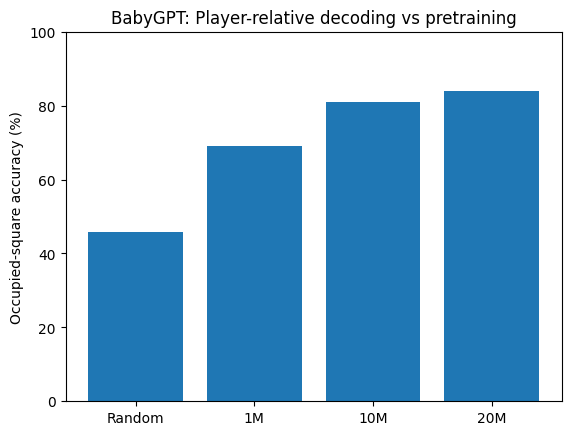

In [49]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

folder = "babygpt_features"
results = {}

# Same player-relative labels for every model
labels = {
    split: torch.tensor(
        np.load(f"{folder}/relative_{split}.npy").reshape(-1, 64),
        dtype=torch.long
    )
    for split in ["train", "val", "test"]
}

for name in ["Random", "1M", "10M", "20M"]:

    # Load final-layer features
    features = {}
    for split in ["train", "val", "test"]:
        data = np.load(f"{folder}/{name}_{split}.npy")
        features[split] = torch.tensor(
            data[:, 3].reshape(-1, 256),
            dtype=torch.float32
        )

    # Normalize using training features only
    mean = features["train"].mean(0)
    std = features["train"].std(0).clamp(min=1e-6)

    for split in features:
        features[split] = (features[split] - mean) / std

    # Train an identical linear probe
    torch.manual_seed(42)
    probe = nn.Linear(256, 192)
    optimizer = torch.optim.AdamW(probe.parameters(), lr=0.001)

    best_loss = float("inf")
    best_weights = None

    for epoch in range(150):
        logits = probe(features["train"]).reshape(-1, 64, 3)
        loss = F.cross_entropy(
            logits.reshape(-1, 3),
            labels["train"].reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            val_logits = probe(features["val"]).reshape(-1, 64, 3)
            val_loss = F.cross_entropy(
                val_logits.reshape(-1, 3),
                labels["val"].reshape(-1)
            )

        if val_loss.item() < best_loss:
            best_loss = val_loss.item()
            best_weights = {
                k: v.clone() for k, v in probe.state_dict().items()
            }

    probe.load_state_dict(best_weights)

    # Evaluate
    with torch.no_grad():
        predictions = probe(features["test"]).reshape(-1, 64, 3).argmax(-1)

    correct = predictions == labels["test"]
    occupied = labels["test"] != 1

    overall = correct.float().mean().item()
    occupied_accuracy = correct[occupied].float().mean().item()

    results[name] = occupied_accuracy

    print(
        f"{name:6s} | Overall: {overall:.2%} | "
        f"Occupied: {occupied_accuracy:.2%}"
    )

# Visualize the comparison
plt.bar(results.keys(), [100 * v for v in results.values()])
plt.ylabel("Occupied-square accuracy (%)")
plt.title("BabyGPT: Player-relative decoding vs pretraining")
plt.ylim(0, 100)
plt.show()


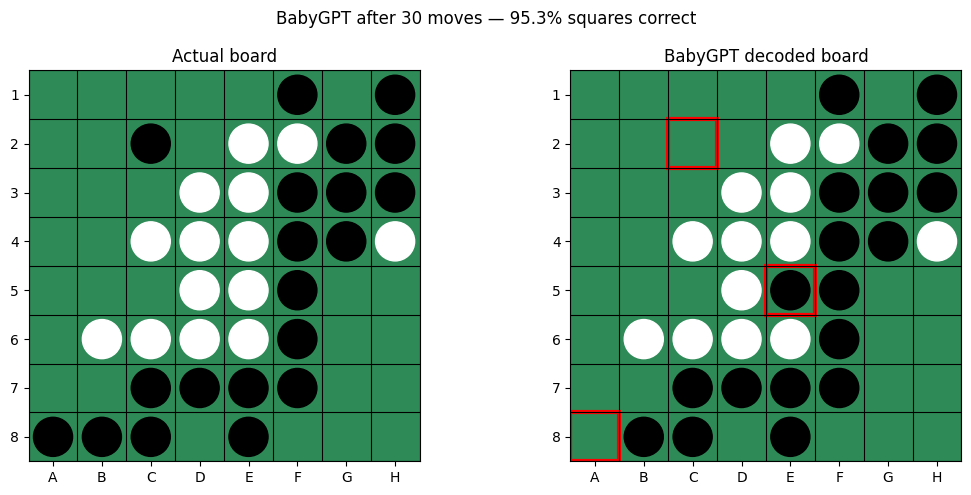

In [50]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

folder = "babygpt_features"

# Load saved 20M features and player-relative labels
X = {}
Y = {}

for split in ["train", "val", "test"]:
    features = np.load(f"{folder}/20M_{split}.npy")
    labels = np.load(f"{folder}/relative_{split}.npy")

    X[split] = torch.tensor(features[:, 3].reshape(-1, 256), dtype=torch.float32)
    Y[split] = torch.tensor(labels.reshape(-1, 64), dtype=torch.long)

# Normalize using training features only
mean = X["train"].mean(0)
std = X["train"].std(0).clamp(min=1e-6)

for split in X:
    X[split] = (X[split] - mean) / std

# Train our linear probe
torch.manual_seed(42)
probe = nn.Linear(256, 192)
optimizer = torch.optim.AdamW(probe.parameters(), lr=0.001)

best_loss = float("inf")
best_weights = None

for epoch in range(150):
    logits = probe(X["train"]).reshape(-1, 64, 3)
    loss = F.cross_entropy(logits.reshape(-1, 3), Y["train"].reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        val_logits = probe(X["val"]).reshape(-1, 64, 3)
        val_loss = F.cross_entropy(
            val_logits.reshape(-1, 3), Y["val"].reshape(-1)
        )

    if val_loss.item() < best_loss:
        best_loss = val_loss.item()
        best_weights = {k: v.clone() for k, v in probe.state_dict().items()}

probe.load_state_dict(best_weights)
probe.eval()

# Select test game 0, after 30 moves (index 5 in our cached positions)
game_index = 0
position_index = 5

sample_index = game_index * 12 + position_index

with torch.no_grad():
    predicted = probe(X["test"][sample_index]).reshape(64, 3).argmax(-1)

predicted = predicted.numpy().reshape(8, 8)
actual = Y["test"][sample_index].numpy().reshape(8, 8)

# Draw actual and reconstructed boards
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, board, title in [
    (axes[0], actual, "Actual board"),
    (axes[1], predicted, "BabyGPT decoded board")
]:
    ax.set_facecolor("seagreen")
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(7.5, -0.5)

    for row in range(8):
        for col in range(8):
            state = board[row, col]

            if state != 1:
                color = "black" if state == 2 else "white"
                ax.add_patch(plt.Circle((col, row), 0.4, color=color))

            # Highlight prediction mistakes
            if title == "BabyGPT decoded board" and state != actual[row, col]:
                ax.add_patch(plt.Rectangle(
                    (col - 0.5, row - 0.5), 1, 1,
                    fill=False, edgecolor="red", linewidth=3
                ))

    ax.set_xticks(range(8), list("ABCDEFGH"))
    ax.set_yticks(range(8), range(1, 9))
    ax.set_xticks(np.arange(9) - 0.5, minor=True)
    ax.set_yticks(np.arange(9) - 0.5, minor=True)
    ax.grid(which="minor", color="black")
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_aspect("equal")
    ax.set_title(title)

accuracy = (predicted == actual).mean()

plt.suptitle(f"BabyGPT after 30 moves — {accuracy:.1%} squares correct")
plt.tight_layout()
plt.show()

# Save the probe and visualization
torch.save({
    "probe": probe.state_dict(),
    "mean": mean,
    "std": std
}, "babygpt_features/probe_20M_relative.pt")

fig.savefig("babygpt_features/board_comparison.png", dpi=200, bbox_inches="tight")
